# PGR107 Python Programming | Home Exam 2026
**Bachelor of Data Science, Kristiania University of Applied Sciences**

**Candidates:** xxx & xxx

## How to use
Run the last coding cell to access the menu, which presents our exam submission.


## Imports

In [83]:
import numpy as np
import pandas as pd
import chardet
import matplotlib.pyplot as plt
import matplotlib.legend as mlegend

## Code

In [84]:
def printMenu():
    print()
    print("Which question do you want to run?")
    print("-----------------------------------")
    print("0. Exit")
    print("1. Question 1 - Supernacci")
    print("2. Question 2 - Dice Game")
    print("3. Question 3 - Coordinates")
    print("4. Question 4 - Matrix Trace")
    print("5. Question 5 - Case Study")
    print("-----------------------------------")
    print()

def pressEnterToContinue():
    try:
        print("\nClick OK to continue... (or enter if in terminal)")
        input()
    except KeyboardInterrupt:
        pass

def menu():
    choice = ' '

    while choice not in ('0'):
        printMenu()

        try:
            choice = input("Enter a number: ")
        except KeyboardInterrupt:
            print("\nExiting...")
            break

        match choice:
            case '1':
                question1()
                pressEnterToContinue()
                choice = ' '
            case '2':
                question2()
                pressEnterToContinue()
                choice = ' '
            case '3':
                question3()
                pressEnterToContinue()
                choice = ' '
            case '4':
                question4()
                pressEnterToContinue()
                choice = ' '
            case '5':
                question5("dataset.csv")
                pressEnterToContinue()
                choice = ' '
            case '0':
                print("Bye")
            case _:
                print("Invalid choice")

---
## Question 1: Supernacci Numbers

The Supernacci numbers `s(n)` are defined as:
- `s(1) = 1`
- `s(n)` is the sum of the last `(n - 1) % 3` Supernacci numbers, or `s(n-1)` if that sum would be empty (i.e. when `(n-1) % 3 == 0`).

**Strategy:** Build the sequence iteratively in a list. For each new term, we use slicing `s[-j:]` and the built-in `sum()` to compute the value.

In [85]:
def question1():
    def supernacci(n):
        s = [1]
        for i in range(2, n + 1):
            j = (i - 1) % 3
            # When (n-1) % 3 == 0, the slice s[-0:] would mean s[0:], which is the entire list, not an empty one.
            if j == 0:
                # Sum would be empty, use previous term instead
                s.append(s[-1])
            else:
                # Sum of the last j elements using slicing
                s.append(sum(s[-j:]))

        return s[n - 1]

    # Output the first 12 Supernacci numbers to verify the pattern
    print("n  | s(n)")
    print("-----------------------------------")
    for n in range(1, 13):
        print(f"{n:<3}| {supernacci(n)}")

---
## Question 2: Gambling Program

Fixing a bugged implementation of a gambling program.

**Bugs fixed:**
- Typos, all "guesss" instances changed to "guess"
- In getDiceGuess() the return statement was indented inside the while loop
- In getDiceGuess() trailing spaces in `'1 '` etc., user input would never match
- In getDiceGuess() returns a string, but dice is an int. Added `int()` conversion
- In rollDice() `random.randint` changed to `rnd.randint`
- In rollDice() `randint(1, 5)` changed to `randint(1, 4)`
- In rollDice() `if dice = guess:` declaration changed to comparison `==`
- In rollDice() Last `if dice = guess` missing the colon :
- None of the functions get called, added function calls

**Architecture changes:**
- Added checkDice function instead of the last `if` chain. It was unnecessarily indented and
  generally bad practice since it is inconvenient to both read and maintain. Added `maxAttempts`
  variable to facilitate this function.
- Removed "global" variables `dice` and `guess`. Since our implementation uses a menu wrapper,
  they aren't technically global, but nonlocal. Regardless the program becomes more robust
  by confining variables within the scope they are required.


In [86]:
import random as rnd

def question2():
    def getDiceGuess():
        guessRaw = ''
        while guessRaw not in ('1', '2', '3', '4'):
            print('Guess the number on a 4-sided dice! Enter a number between 1 and 4:')
            guessRaw = input()
        return int(guessRaw)

    def checkDice(dice, guess, attempts, maxAttempts):
        if dice == guess:
            print('Correct! Number of attempts:', attempts)
            return True
        else:
            print('Wrong! Remaining attempts:', maxAttempts - attempts)
            return False

    def rollDice():
        roll = rnd.randint(1, 4)
        return roll

    dice = rollDice()
    maxAttempts = 4

    for attempts in range(1, maxAttempts + 1): # lower boundary inclusive, upper exclusive
        guess = getDiceGuess()
        if checkDice(dice, guess, attempts, maxAttempts):
            return

    print('Game over! The number was', dice)

---
## Question 3:

Use the following approximations:

`1 degree of latitude = 111 km`

`1 degree of longitude = 68 km`

Assume that each city has a square shape and that the city size can be added from the center in each direction, as you can see in the image. Ignore the curvature of the Earth when working with latitude and longitude.

a) (6 points) Find the nearest city and POI
 - Function that returns the closest POI for a given pair of coordinates,
 - Function that returns the closest city for a given pair of coordinates.
   Then ask the user to enter a latitude and longitude, and print the closest city and closest POI.

b) (6 points) Compute city boundaries
 - Extend the city data by computing the city boundaries: north, south, east, west.

c) (6 points) Assign POIs to cities
For each city, determine which POIs are located inside its boundaries.
A POI belongs to a city if:
 - its latitude lies between the south and north boundaries
 - its longitude lies between the west and east boundaries

d) (6 points) Compute average POI rating per city
For each city, compute the average customer rating of all POIs located in that city.

e) (6 points) Order POIs by distance from the city center
For each city, create a list of POI names ordered by their distance from the city center, from nearest to farthest.

In [87]:
def question3():

    latitudeMultiplier = 111
    longitudeMultiplier = 68

    cities = {'Bergen':    [60.364098, 5.404422,  15],
              'Oslo':      [59.926959, 10.779454, 10],
              'Trondheim': [63.433654, 10.390277, 5]
    }

    poi = {(63.426806, 10.396712): ['Nidarosdommen',     4.5],
           (59.926699, 10.701075): ['Vigelandsparken',   5],
           (59.907704, 10.753163): ['Operahuset',        4],
           (60.397561, 5.322833):  ['Bryggen',           4.5],
           (60.387639, 5.321623):  ['Universitetmuseet', 5],
           (60.342901, 5.336796):  ['Gamlehaugen',       4]
    }

    # Task a: Find the nearest city and POI
    def returnClosestPoi(userCoords):
        shortestDistance = np.inf
        closestPoi       = None
        closestCoords    = None

        print("\n--| Searching POIs |--")
        for coords, data in poi.items():
            poiLatitude  = coords[0]
            poiLongitude = coords[1]
            print(f"  Testing POI: {data[0]:<20} at ({poiLatitude}, {poiLongitude})")

            latitudeDistance  = abs(userCoords[0] - poiLatitude)  * latitudeMultiplier
            longitudeDistance = abs(userCoords[1] - poiLongitude) * longitudeMultiplier
            distance = latitudeDistance + longitudeDistance

            if distance < shortestDistance:
                shortestDistance = distance
                closestPoi       = data
                closestCoords    = coords

        return closestPoi, closestCoords

    def returnClosestCity(userCoords):
        shortestDistance = np.inf
        closestCity      = None
        closestCoords    = None

        print("\n--| Searching Cities |--")
        for city, values in cities.items():
            cityLatitude  = values['center'][0]
            cityLongitude = values['center'][1]
            print(f"  Testing City: {city:<12} at ({cityLatitude}, {cityLongitude})")

            latitudeDistance  = abs(userCoords[0] - cityLatitude)  * latitudeMultiplier
            longitudeDistance = abs(userCoords[1] - cityLongitude) * longitudeMultiplier
            distance = latitudeDistance + longitudeDistance

            if distance < shortestDistance:
                shortestDistance = distance
                closestCity      = city
                closestCoords    = [cityLatitude, cityLongitude]

        return closestCity, closestCoords

    def getUserCoords():
        try:
            while True:
                try:
                    userLatitude = float(input("Enter your latitude: "))
                    break
                except ValueError:
                    print("Invalid input.")

            while True:
                try:
                    userLongitude = float(input("Enter your longitude: "))
                    break
                except ValueError:
                    print("Invalid input.")

            return [userLatitude, userLongitude]

        except KeyboardInterrupt:
            print("\nExiting...")
            return None

    # Task b: Extend cities with boundaries
    def setCityBoundaries():
        for city, values in cities.items():
            lat, lon, size = values[0], values[1], values[2]
            cities[city] = {
                'center': [lat, lon],
                'size':   size,
                'north':  lat + (size / latitudeMultiplier),
                'south':  lat - (size / latitudeMultiplier),
                'east':   lon + (size / longitudeMultiplier),
                'west':   lon - (size / longitudeMultiplier)
            }

    # Task c: Assign POIs to cities
    def setCityPois():
        for city in cities:
            cities[city]['pois'] = []

        for coords, data in poi.items():
            poiLat, poiLon = coords[0], coords[1]

            for city, values in cities.items():
                insideLat = values['south'] <= poiLat <= values['north']
                insideLon = values['west']  <= poiLon <= values['east']

                if insideLat and insideLon:
                    values['pois'].append(data)

    # Task d: Compute average POI rating per city
    def computeAvgRatings():
        for city, values in cities.items():
            ratings = [p[1] for p in values['pois']]
            values['avgRating'] = sum(ratings) / len(ratings)

    # Task e: Order POIs by distance from city center
    def sortPoisByDistance():
        for city, values in cities.items():
            cityLat = values['center'][0]
            cityLon = values['center'][1]

            distances = []
            for coords, data in poi.items():
                if data in values['pois']:
                    latDist  = abs(cityLat - coords[0]) * latitudeMultiplier
                    lonDist  = abs(cityLon - coords[1]) * longitudeMultiplier
                    distances.append((latDist + lonDist, data[0]))

            distances.sort()
            values['poisByDistance'] = distances

    # Main flow
    print("Find the closest POI or city based on your coordinates")
    userCoords = getUserCoords()

    if userCoords is None:
            return

    setCityBoundaries()
    setCityPois()
    computeAvgRatings()
    sortPoisByDistance()

    closestPoi,  poiCoords  = returnClosestPoi(userCoords)
    closestCity, cityCoords = returnClosestCity(userCoords)

    print("\n--| Results |--")
    print(f"  {'User coordinates:':<18} {'':<20}  ({userCoords[0]}, {userCoords[1]})")
    print(f"  {'Closest POI:':<18} {closestPoi[0]:<20}  ({poiCoords[0]}, {poiCoords[1]})")
    print(f"  {'Closest City:':<18} {closestCity:<20}  ({cityCoords[0]}, {cityCoords[1]})")

    print("\n--| City Boundaries |--")
    for city, values in cities.items():
        print(f"  {city} (center: {values['center']}, size: {values['size']} km)")
        print(f"    north: {values['north']:.6f}    south: {values['south']:.6f}")
        print(f"    east:  {values['east']:9.6f}    west:  {values['west']:9.6f}")

    print("\n--| POIs per City |--")
    for city, values in cities.items():
        print(f"  {city:<12} {[f'{p[0]} ({p[1]})' for p in values['pois']]}")
    print()

    print("\n--| Average POI Rating per City |--")
    for city, values in cities.items():
        print(f"  {city:<12} avg rating: {values['avgRating']:.2f}")

    print("\n--| POIs by Distance from City Center |--")
    for city, values in cities.items():
        print(f"  {city}")
        for distance, name in values['poisByDistance']:
            print(f"    {name:<20} {distance:.2f} km")

    print()

---
## Question 4: Matrix Trace

Given a rank 2 numpy array A (a matrix), check whether the number of columns equals the number of rows. If (and only if) they coincide, compute and output the sum of elements on the main diagonal.

**Strategy:** First implement manually by iterating over the diagonal indices `A[i, i]`. Then verify the result using NumPy's built-in `np.trace()` to confirm correctness.

In [88]:
def question4():
    def trace(A):
        # check whether the number of columns equals the number of rows
        if A.shape[0] != A.shape[1]:
            print("Invalid matrix, trace operation aborted.")
            return

        # Manual implementation: sum diagonal elements A[i, i]
        total = 0
        for i in range(A.shape[0]):
            total += A[i, i]

        print(f"Manual trace:    {total}")

        # np.trace() used to verify our manual result is correct
        print(f"np.trace():      {np.trace(A)}\n")

    A = np.array([[1, 2, 3],
                  [4, 5, 6],
                  [7, 8, 9]])
    B = np.array([[3, 1, 7],
                  [7, 1, 4],
                  [2, 8, 5]])
    C = np.array([[1, 2, 3],
                  [4, 5, 6]])


    print(f"Matrix A:\n{A}")
    trace(A)
    print(f"Matrix B:\n{B}")
    trace(B)
    print(f"Matrix C:\n{C}")
    trace(C)

### 5.1 — Data Selection

We downloaded the *karakterstatistikk* dataset from Utdanningsdirektoratet covering Oslo high schools. Filters applied on download and in code:

- **Enhet (school level):** Individual Oslo schools only (`EnhetNivaa == 3`, `Fylke == 'Oslo'`). National, county, and aggregate rows are excluded.
- **Karaktertype:** Standpunkt. Written exams are externally set and marked, making them a more objective and comparable signal than standpunkt grades, which are school-set and therefore more susceptible to institutional grade inflation.
- **School years:** 2020–21 through 2024–25 (five years — pre-COVID baseline through post-COVID recovery).
- **Subject selection:** All available written exam subjects for Oslo schools. Subjects are grouped into *utdanningsprogrammer* (education programmes) using the two-character prefix of the `Vurderingsfagkode` (e.g. `RE` → Realfag, `SA` → Samfunnsfag).

The file is a tab-separated, UTF-16-LE encoded CSV. Encoding is detected automatically, grade columns converted from Norwegian decimal format (comma → dot), and suppressed values (`*`) replaced with `NaN`.

---

### 5.2 — Exploratory Visualization

See the visualizations generated by the implementation below. Each panel is labeled and covers a distinct aspect of the data.

---

### 5.3 — Problem Definition and Analysis

**Research question:**

Have standpunkt grades at Oslo high schools drifted upward from 2020–21 to 2024–25, and does the pattern differ between utdanningsprogrammer?

**Background:**

During and after the COVID-19 pandemic, grading practices became an important topic in education because normal teaching, assessment, and exam routines were disrupted. International research has discussed grade inflation during this period, meaning that grades may increase without a matching increase in student performance.

This project focuses on **standpunkt grades** in Oslo high schools. Standpunkt grades are final grades set by the school, so they are suitable for studying whether school-level grading patterns changed over time. By analyzing standpunkt grades from 2020–21 to 2024–25, the project investigates whether average grades drifted upward across Oslo schools, and whether the trend differs between subject/programme groups.

**Hypotheses:**

- **H1 (Systemic grade drift):** Mean standpunkt grades across Oslo high schools changed from 2020–21 to 2024–25. If the mean increased, this may indicate upward grade drift in school-set grades during the COVID/post-COVID period.
- **H2 (Programme-level variation):** The rate and direction of grade drift differs by utdanningsprogram. Some programme groups, such as Realfag or Samfunnsfag, may show stronger or more consistent changes than others.

**Implementation — visualizations used:**

The analysis uses a multi-panel figure (`fig.add_subplot` / `fig.subplots_adjust`) with the following chart types:

- **Histogram** (`plt.hist`) — overlay the grade distribution for the first year (2020–21) and the last year (2024–25) using alpha transparency, showing any rightward shift in the overall distribution.
- **Error bars** (`plt.errorbar`) — plot the overall mean written exam grade per year with ±1 standard deviation bars, showing whether the aggregate trend is upward and how variance evolves. Per-programme lines are overlaid lightly in the background.
- **Line plot** (`plt.plot`) — one line per utdanningsprogram showing average grade across years, making programme-level trends and their relative ordering visible over time.
- **Scatter plot** (`plt.plot` with markers) — individual Oslo school averages per year per programme, revealing how consistently (or inconsistently) the drift appears across institutions.
- **Contour/density plot** (`plt.contour` on `np.meshgrid`) — 2D density of (avg grade 2020–21, avg grade 2024–25) pairs per school/programme. A reference diagonal (y = x) marks zero grade change; schools above it have inflated. The density contour shows where most schools cluster relative to that boundary.
- **Legends** (`ax.legend`, `ax.add_artist`) — programmes are consistently coloured across all panels. The scatter+contour panel uses two separate legends (programmes + contour reference) via `ax.add_artist()`.

Each subplot is labeled with title, x-axis label, and y-axis label. Conclusions are drawn from what the charts show.

---

### Sources

Utdanningsdirektoratet. (2025). *Karakterstatistikk for videregående skole.*
https://www.udir.no/tall-og-forskning/statistikk/statistikk-videregaende-skole/karakterer-vgs/


In [89]:
def question5(filepath="dataset.csv"):
    # ------------------------------------------------------------
    # 1. Load and clean dataset
    # ------------------------------------------------------------
    def load_dataset(filepath):
        # Partially read file to check encoding
        with open(filepath, "rb") as f:
            raw = f.read(20000)
        result = chardet.detect(raw)
        encoding = result["encoding"]
        print(f"Detected encoding: {encoding}")

        # Open file
        with open(filepath, "r", encoding=encoding, errors="replace") as f:
            first_line = f.readline().strip()

        # Create dataframe
        skiprows = 1 if first_line.startswith("sep=") else 0

        df = pd.read_csv(
            filepath,
            sep="\t",
            encoding=encoding,
            skiprows=skiprows
        )

        # When selecting "Oslo" per task description in category "Enhet", "Hele landet" which is the parent category will also be selected.
        # we therefore need to filter specifically for Oslo.
        df = df[
            (df["Fylke"] == "Oslo") &
            (df["EnhetNivaa"] == 3) # 3: individual school
        ].reset_index()

        # Find all columns which contain yearly statistics.
        # all columns which contain this follows this pattern: 2020-21.Standpunkt.Alle eierformer.Alle kjønn.Snittkarakter
        stat_cols = [
            col for col in df.columns
            if col[:4].isdigit() and "." in col
        ]

        # Iterate through the identified columns, and cleans the data
        for col in stat_cols:
            df[col] = (
                df[col]
                .replace("*", np.nan) # we don't want to process suppressed data
                .astype(str)
                .str.replace(",", ".") # Python needs decimal points to understand numbers as floats.
            )
            df[col] = pd.to_numeric(df[col], errors="coerce")

        return df

    df = load_dataset(filepath)

    # ------------------------------------------------------------
    # 2. Select standpunkt grade and student-count columns
    # ------------------------------------------------------------
    standpunkt_grade_cols = [
        col for col in df.columns
        if "Standpunkt" in col and "Snittkarakter" in col
    ]

    years = sorted(
        list(set(col.split(".")[0] for col in standpunkt_grade_cols)),
        key=lambda year: int(year.split("-")[0])
    )

    grade_cols = []
    count_cols = {}

    for year in years:
        possible_grade_cols = [
            col for col in standpunkt_grade_cols
            if col.startswith(year + ".")
            and "Alle eierformer" in col
            and "Alle kjønn" in col
        ]

        if len(possible_grade_cols) == 0:
            possible_grade_cols = [
                col for col in standpunkt_grade_cols
                if col.startswith(year + ".")
            ]

        grade_col = possible_grade_cols[0]
        grade_cols.append(grade_col)

        possible_count_cols = [
            col for col in df.columns
            if col.startswith(year + ".")
            and "Standpunkt" in col
            and "Antall elever" in col
            and "Alle eierformer" in col
            and "Alle kjønn" in col
        ]

        if len(possible_count_cols) == 0:
            possible_count_cols = [
                col for col in df.columns
                if col.startswith(year + ".")
                and "Standpunkt" in col
                and "Antall elever" in col
            ]

        count_cols[year] = possible_count_cols[0] if len(possible_count_cols) > 0 else None

    # ------------------------------------------------------------
    # 3. Group subjects into programme categories
    # ------------------------------------------------------------
    three_prefix_map = {
        "REA": "Realfag",
        "MAT": "Realfag",
        "NAT": "Realfag",
        "BIO": "Realfag",
        "FYS": "Realfag",
        "KJE": "Realfag",
        "INF": "Realfag",
        "TEK": "Realfag",

        "SAM": "Samfunnsfag",
        "SAF": "Samfunnsfag",
        "SOS": "Samfunnsfag",
        "POL": "Samfunnsfag",
        "HIS": "Samfunnsfag",
        "GEO": "Samfunnsfag",
        "ØKO": "Samfunnsfag",

        "NOR": "Fellesfag",
        "ENG": "Fellesfag",
        "KRO": "Fellesfag",
        "REL": "Fellesfag",

        "FSP": "Fremmedspråk",
        "PSP": "Fremmedspråk",
        "SPR": "Fremmedspråk",
        "FRE": "Fremmedspråk",
        "TYS": "Fremmedspråk",
        "SPA": "Fremmedspråk",

        "IDR": "Idrettsfag",

        "MUS": "Musikk/dans/drama",
        "DRA": "Musikk/dans/drama",
        "DAN": "Musikk/dans/drama",

        "MED": "Medier og kommunikasjon",

        "ADI": "Yrkesfag",
        "AKT": "Yrkesfag",
        "AKV": "Yrkesfag",
        "AMB": "Yrkesfag",
        "BUA": "Yrkesfag",
        "ELE": "Yrkesfag",
        "ELK": "Yrkesfag",
        "HEA": "Yrkesfag",
        "HES": "Yrkesfag",
        "KOS": "Yrkesfag",
        "YFF": "Yrkesfag",
    }

    two_prefix_map = {
        "RE": "Realfag",
        "SA": "Samfunnsfag",

        "FS": "Fremmedspråk",
        "PS": "Fremmedspråk",
        "SP": "Fremmedspråk",

        "NO": "Fellesfag",
        "EN": "Fellesfag",
        "MA": "Realfag",
        "NA": "Realfag",

        "ID": "Idrettsfag",

        "MU": "Musikk/dans/drama",
        "DA": "Musikk/dans/drama",
        "DR": "Musikk/dans/drama",

        "MO": "Medier og kommunikasjon",

        "AU": "Yrkesfag",
        "EL": "Yrkesfag",
        "BU": "Yrkesfag",
        "LB": "Yrkesfag",
        "LO": "Yrkesfag",
        "SL": "Yrkesfag",
    }

    def classify_program(code):
        code = str(code).upper().strip()

        prefix3 = code[:3]
        prefix2 = code[:2]

        if prefix3 in three_prefix_map:
            return three_prefix_map[prefix3]

        if prefix2 in two_prefix_map:
            return two_prefix_map[prefix2]

        return "Andre"

    df["program"] = df["Vurderingsfagkode"].apply(classify_program)

    # ------------------------------------------------------------
    # 4. Convert wide dataset to long format
    # ------------------------------------------------------------
    records = []

    for _, row in df.iterrows():
        for year, grade_col in zip(years, grade_cols):
            grade = row[grade_col]

            if pd.isna(grade):
                continue

            count_col = count_cols[year]
            n_students = row[count_col] if count_col is not None else 1

            records.append({
                "school": row["EnhetNavn"],
                "subject_code": row["Vurderingsfagkode"],
                "subject_name": row["Vurderingsfagnavn"],
                "program": row["program"],
                "year": year,
                "grade": grade,
                "n_students": n_students
            })

    df_long = pd.DataFrame(records)

    df_long["n_students"] = pd.to_numeric(
        df_long["n_students"],
        errors="coerce"
    ).fillna(1)

    df_long.loc[df_long["n_students"] <= 0, "n_students"] = 1

    # ------------------------------------------------------------
    # 5. Weighted statistics helpers
    # ------------------------------------------------------------
    def weighted_mean(values, weights):
        values = np.asarray(values, dtype=float)
        weights = np.asarray(weights, dtype=float)

        mask = (~np.isnan(values)) & (~np.isnan(weights)) & (weights > 0)

        if mask.sum() == 0:
            return np.nan

        return np.average(values[mask], weights=weights[mask])

    def weighted_std(values, weights):
        values = np.asarray(values, dtype=float)
        weights = np.asarray(weights, dtype=float)

        mask = (~np.isnan(values)) & (~np.isnan(weights)) & (weights > 0)

        if mask.sum() == 0:
            return np.nan

        mean = np.average(values[mask], weights=weights[mask])
        variance = np.average((values[mask] - mean) ** 2, weights=weights[mask])

        return np.sqrt(variance)

    def program_year_mean(program, year):
        subset = df_long[
            (df_long["program"] == program) &
            (df_long["year"] == year)
        ]

        if subset.empty:
            return np.nan

        return weighted_mean(subset["grade"], subset["n_students"])

    # ------------------------------------------------------------
    # 6. Summary statistics
    # ------------------------------------------------------------
    print("\n--| Dataset Summary |--")
    print(f"Rows after Oslo-school filter: {len(df)}")
    print(f"Rows in long standpunkt dataset: {len(df_long)}")
    print(f"Schools: {df_long['school'].nunique()}")
    print(f"Subjects: {df_long['subject_code'].nunique()}")
    print(f"Years: {', '.join(years)}")

    print("\n--| Observations per Year |--")
    for year in years:
        subset = df_long[df_long["year"] == year]
        print(
            f"{year}: "
            f"{subset['grade'].count()} observations, "
            f"{int(subset['n_students'].sum())} students"
        )

    programme_rows = []

    for program in sorted(df_long["program"].unique()):
        subset = df_long[df_long["program"] == program]

        programme_rows.append({
            "program": program,
            "mean": weighted_mean(subset["grade"], subset["n_students"]),
            "std": weighted_std(subset["grade"], subset["n_students"]),
            "count": subset["grade"].count(),
            "students": subset["n_students"].sum()
        })

    programme_stats = pd.DataFrame(programme_rows).sort_values("mean")
    programs_rank = programme_stats["program"].tolist()

    print("\n--| Programme Summary, lowest mean to highest mean |--")
    for _, row in programme_stats.iterrows():
        print(
            f"{row['program']:<25} "
            f"avg={row['mean']:.2f} "
            f"std={row['std']:.2f} "
            f"n={int(row['count'])} "
            f"students={int(row['students'])}"
        )

    year_means = []
    year_stds = []

    print("\n--| Year-by-Year Mean Standpunkt Grades |--")
    for year in years:
        subset = df_long[df_long["year"] == year]

        mean = weighted_mean(subset["grade"], subset["n_students"])
        std = weighted_std(subset["grade"], subset["n_students"])

        year_means.append(mean)
        year_stds.append(std)

        print(
            f"{year}: "
            f"mean={mean:.2f}, "
            f"std={std:.2f}, "
            f"n={subset['grade'].count()}"
        )

    yr_first = years[0]
    yr_last = years[-1]
    overall_change = year_means[-1] - year_means[0]

    print("\n--| H1 Overall Change |--")
    print(f"{yr_first} to {yr_last}: {overall_change:+.2f} grade points")

    # ------------------------------------------------------------
    # 7. School-programme-year averages
    # ------------------------------------------------------------
    school_program_rows = []

    grouped = df_long.groupby(["school", "program", "year"])

    for (school, program, year), group in grouped:
        school_program_rows.append({
            "school": school,
            "program": program,
            "year": year,
            "grade": weighted_mean(group["grade"], group["n_students"]),
            "n_students": group["n_students"].sum()
        })

    school_program_year = pd.DataFrame(school_program_rows)

    programme_changes = []

    for program in programs_rank:
        first_mean = program_year_mean(program, yr_first)
        last_mean = program_year_mean(program, yr_last)

        if pd.isna(first_mean) or pd.isna(last_mean):
            change = np.nan
        else:
            change = last_mean - first_mean

        programme_changes.append({
            "program": program,
            "first_mean": first_mean,
            "last_mean": last_mean,
            "change": change
        })

    programme_changes = pd.DataFrame(programme_changes)

    print("\n--| H2 Programme Changes |--")
    for _, row in programme_changes.sort_values("change").iterrows():
        if pd.isna(row["change"]):
            continue

        print(
            f"{row['program']:<25} "
            f"{yr_first}={row['first_mean']:.2f}, "
            f"{yr_last}={row['last_mean']:.2f}, "
            f"change={row['change']:+.2f}"
        )

    # ------------------------------------------------------------
    # 8. Colors and markers
    # ------------------------------------------------------------
    n_programs = len(programs_rank)

    colors = [plt.cm.tab10(i % 10) for i in range(n_programs)]
    program_color = dict(zip(programs_rank, colors))

    markers = ["o", "s", "^", "D", "v", "P", "*", "X", "h", "p"]

    # ------------------------------------------------------------
    # 9. Create 3 x 2 visualization
    # ------------------------------------------------------------
    fig = plt.figure(figsize=(16, 14))
    fig.subplots_adjust(hspace=0.65, wspace=0.35)

    # Panel 1: Histogram
    ax1 = fig.add_subplot(3, 2, 1)

    first_data = df_long[df_long["year"] == yr_first]
    last_data = df_long[df_long["year"] == yr_last]

    bins = np.linspace(1, 6, 18)

    ax1.hist(
        first_data["grade"],
        bins=bins,
        weights=first_data["n_students"],
        histtype="stepfilled",
        alpha=0.55,
        density=True,
        label=yr_first
    )

    ax1.hist(
        last_data["grade"],
        bins=bins,
        weights=last_data["n_students"],
        histtype="stepfilled",
        alpha=0.55,
        density=True,
        label=yr_last
    )

    ax1.set(
        title=f"H1: Standpunkt Distribution, {yr_first} vs {yr_last}",
        xlabel="Standpunkt grade",
        ylabel="Density"
    )

    ax1.set_xlim(1, 6)
    ax1.legend(loc="upper left", frameon=True)

    # Panel 2: Overall mean with error bars
    ax2 = fig.add_subplot(3, 2, 2)

    x = np.arange(len(years))

    for program in programs_rank:
        means = [program_year_mean(program, year) for year in years]

        if not all(pd.isna(means)):
            ax2.plot(
                x,
                means,
                color=program_color[program],
                linewidth=1,
                alpha=0.35,
                marker="."
            )

    ax2.errorbar(
        x,
        year_means,
        yerr=year_stds,
        color="black",
        capsize=5,
        linewidth=2.5,
        marker="o",
        markersize=7,
        elinewidth=1.5,
        label="All programmes, mean +/- std",
        zorder=5
    )

    ax2.set(
        title="H1: Overall Mean Standpunkt Grade per Year",
        xlabel="Year",
        ylabel="Mean standpunkt grade"
    )

    ax2.set_xticks(x)
    ax2.set_xticklabels(years, rotation=30, fontsize=8)
    ax2.set_ylim(1, 6)
    ax2.legend(loc="upper left", fontsize=8, frameon=True)

    # Panel 3: Programme trend lines
    ax3 = fig.add_subplot(3, 2, 3)

    for i, program in enumerate(programs_rank):
        means = [program_year_mean(program, year) for year in years]

        if all(pd.isna(means)):
            continue

        ax3.plot(
            years,
            means,
            color=program_color[program],
            label=program,
            linewidth=2,
            marker=markers[i % len(markers)],
            markersize=5
        )

    ax3.set(
        title="H2: Average Standpunkt Grade by Programme",
        xlabel="Year",
        ylabel="Mean standpunkt grade"
    )

    ax3.set_ylim(1, 6)

    for tick in ax3.get_xticklabels():
        tick.set_rotation(30)
        tick.set_fontsize(8)

    ax3.legend(loc="upper left", fontsize=7, frameon=True)

    # Panel 4: School-programme averages by year
    ax4 = fig.add_subplot(3, 2, 4)

    year_index = {year: i for i, year in enumerate(years)}
    jitter = np.linspace(-0.28, 0.28, n_programs)

    for pi, program in enumerate(programs_rank):
        rows = school_program_year[
            school_program_year["program"] == program
        ]

        ax4.plot(
            [year_index[year] + jitter[pi] for year in rows["year"]],
            rows["grade"],
            marker=markers[pi % len(markers)],
            color=program_color[program],
            markersize=5,
            alpha=0.55,
            linewidth=0,
            label=program
        )

    ax4.set_xticks(range(len(years)))
    ax4.set_xticklabels(years, rotation=30, fontsize=8)
    ax4.set_ylim(1, 6)

    ax4.set(
        title="H2: School-Programme Average Standpunkt Grades",
        xlabel="Year",
        ylabel="Average standpunkt grade"
    )

    program_handles = [
        plt.Line2D(
            [0],
            [0],
            marker=markers[i % len(markers)],
            color=program_color[programs_rank[i]],
            linewidth=0,
            markersize=6,
            label=programs_rank[i]
        )
        for i in range(n_programs)
    ]

    ax4.legend(
        handles=program_handles,
        loc="upper left",
        fontsize=6,
        frameon=True
    )

    # Panel 5: First year vs last year
    ax5 = fig.add_subplot(3, 2, 5)

    first_df = school_program_year[
        school_program_year["year"] == yr_first
    ][["school", "program", "grade"]].rename(
        columns={"grade": "grade_first"}
    )

    last_df = school_program_year[
        school_program_year["year"] == yr_last
    ][["school", "program", "grade"]].rename(
        columns={"grade": "grade_last"}
    )

    compare_df = pd.merge(
        first_df,
        last_df,
        on=["school", "program"],
        how="inner"
    )

    if compare_df.empty:
        ax5.text(
            0.5,
            0.5,
            "No matching school-programme pairs\nbetween first and last year",
            ha="center",
            va="center",
            transform=ax5.transAxes
        )

        ax5.set_xlim(1, 6)
        ax5.set_ylim(1, 6)

    else:
        x_points = compare_df["grade_first"].values
        y_points = compare_df["grade_last"].values

        diag_min = max(1, min(x_points.min(), y_points.min()) - 0.3)
        diag_max = min(6, max(x_points.max(), y_points.max()) + 0.3)

        ax5.plot(
            [diag_min, diag_max],
            [diag_min, diag_max],
            "k--",
            linewidth=1,
            alpha=0.7
        )

        scatter_handles = []

        for pi, program in enumerate(programs_rank):
            subset = compare_df[compare_df["program"] == program]

            if subset.empty:
                continue

            handle = ax5.plot(
                subset["grade_first"],
                subset["grade_last"],
                marker=markers[pi % len(markers)],
                color=program_color[program],
                markersize=6,
                alpha=0.7,
                linewidth=0,
                label=program
            )[0]

            scatter_handles.append(handle)

        if len(compare_df) >= 5:
            padding = 0.3

            x_grid = np.linspace(
                x_points.min() - padding,
                x_points.max() + padding,
                60
            )

            y_grid = np.linspace(
                y_points.min() - padding,
                y_points.max() + padding,
                60
            )

            X, Y = np.meshgrid(x_grid, y_grid)
            Z = np.zeros_like(X)

            bandwidth = 0.25

            for x_value, y_value in zip(x_points, y_points):
                Z += np.exp(
                    -((X - x_value) ** 2 + (Y - y_value) ** 2)
                    / (2 * bandwidth ** 2)
                )

            ax5.contour(X, Y, Z, levels=6, cmap="RdGy")

        ax5.set_xlim(diag_min, diag_max)
        ax5.set_ylim(diag_min, diag_max)

        leg1 = mlegend.Legend(
            ax5,
            scatter_handles,
            [h.get_label() for h in scatter_handles],
            loc="upper left",
            fontsize=6,
            title="Programme",
            frameon=True
        )

        diagonal_handle = plt.Line2D(
            [0],
            [0],
            color="black",
            linewidth=1,
            linestyle="--"
        )

        contour_handle = plt.Line2D(
            [0],
            [0],
            color="dimgray",
            linewidth=1.5
        )

        leg2 = mlegend.Legend(
            ax5,
            [diagonal_handle, contour_handle],
            ["No change", "Density contour"],
            loc="lower right",
            fontsize=6,
            frameon=True
        )

        ax5.add_artist(leg1)
        ax5.add_artist(leg2)

    ax5.set(
        title=(
            f"H1/H2: School-Programme Averages, {yr_first} vs {yr_last}\n"
            f"Above diagonal = higher grade in {yr_last}"
        ),
        xlabel=f"Average standpunkt grade {yr_first}",
        ylabel=f"Average standpunkt grade {yr_last}"
    )

    # Panel 6: Change by programme
    ax6 = fig.add_subplot(3, 2, 6)

    deltas = [
        programme_changes.loc[
            programme_changes["program"] == program,
            "change"
        ].iloc[0]
        for program in programs_rank
    ]

    x_bar = np.arange(len(programs_rank))

    ax6.bar(
        x_bar,
        deltas,
        alpha=0.85,
        color=[program_color[program] for program in programs_rank]
    )

    ax6.axhline(0, color="black", linewidth=0.8)

    ax6.set_xticks(x_bar)
    ax6.set_xticklabels(
        [program[:18] for program in programs_rank],
        rotation=45,
        ha="right",
        fontsize=8
    )

    ax6.set(
        title=f"H2: Change in Mean Standpunkt Grade by Programme\n{yr_first} to {yr_last}",
        xlabel="Programme",
        ylabel="Change in mean grade"
    )

    plt.suptitle(
        "Oslo High Schools - Standpunkt Grade Drift Analysis, 2020-2025",
        fontsize=14,
        fontweight="bold",
        y=1.01
    )

    plt.show()

    # ------------------------------------------------------------
    # 10. Interpretation
    # ------------------------------------------------------------
    print("\n--| Interpretation |--")

    if overall_change > 0.05:
        print(
            f"H1 supported: the overall weighted mean standpunkt grade increased "
            f"by {overall_change:.2f} grade points from {yr_first} to {yr_last}."
        )
    elif overall_change < -0.05:
        print(
            f"H1 not supported: the overall weighted mean standpunkt grade decreased "
            f"by {abs(overall_change):.2f} grade points from {yr_first} to {yr_last}."
        )
    else:
        print(
            f"H1 weak/neutral: the overall weighted mean standpunkt grade changed "
            f"by only {overall_change:+.2f} grade points from {yr_first} to {yr_last}."
        )

    positive_changes = programme_changes[programme_changes["change"] > 0.05]
    negative_changes = programme_changes[programme_changes["change"] < -0.05]

    if len(positive_changes) > len(negative_changes):
        print(
            "H2: Most programme groups increased, suggesting a broad upward drift."
        )
    elif len(positive_changes) == 0 and len(negative_changes) == 0:
        print(
            "H2: Programme-level changes are small overall, so there is limited "
            "evidence of strong programme-specific drift."
        )
    else:
        print(
            "H2: Programme-level changes are mixed, so the drift is not equally "
            "strong across all programme groups."
        )

    print(
        "This analysis uses standpunkt grades, so it measures school-set grade "
        "patterns across Oslo high schools."
    )





Which question do you want to run?
-----------------------------------
0. Exit
1. Question 1 - Supernacci
2. Question 2 - Dice Game
3. Question 3 - Coordinates
4. Question 4 - Matrix Trace
5. Question 5 - Case Study
-----------------------------------

Detected encoding: utf-16-le

--| Dataset Summary |--
Rows after Oslo-school filter: 4651
Rows in long standpunkt dataset: 9541
Schools: 39
Subjects: 574
Years: 2020-21, 2021-22, 2022-23, 2023-24, 2024-25

--| Observations per Year |--
2020-21: 1879 observations, 111512 students
2021-22: 1880 observations, 113629 students
2022-23: 1904 observations, 114464 students
2023-24: 1935 observations, 117305 students
2024-25: 1943 observations, 120021 students

--| Programme Summary, lowest mean to highest mean |--
Realfag                   avg=4.00 std=0.71 n=2462 students=137423
Yrkesfag                  avg=4.07 std=0.54 n=330 students=12086
Andre                     avg=4.31 std=0.72 n=999 students=35236
Fellesfag                 avg=4.43 st

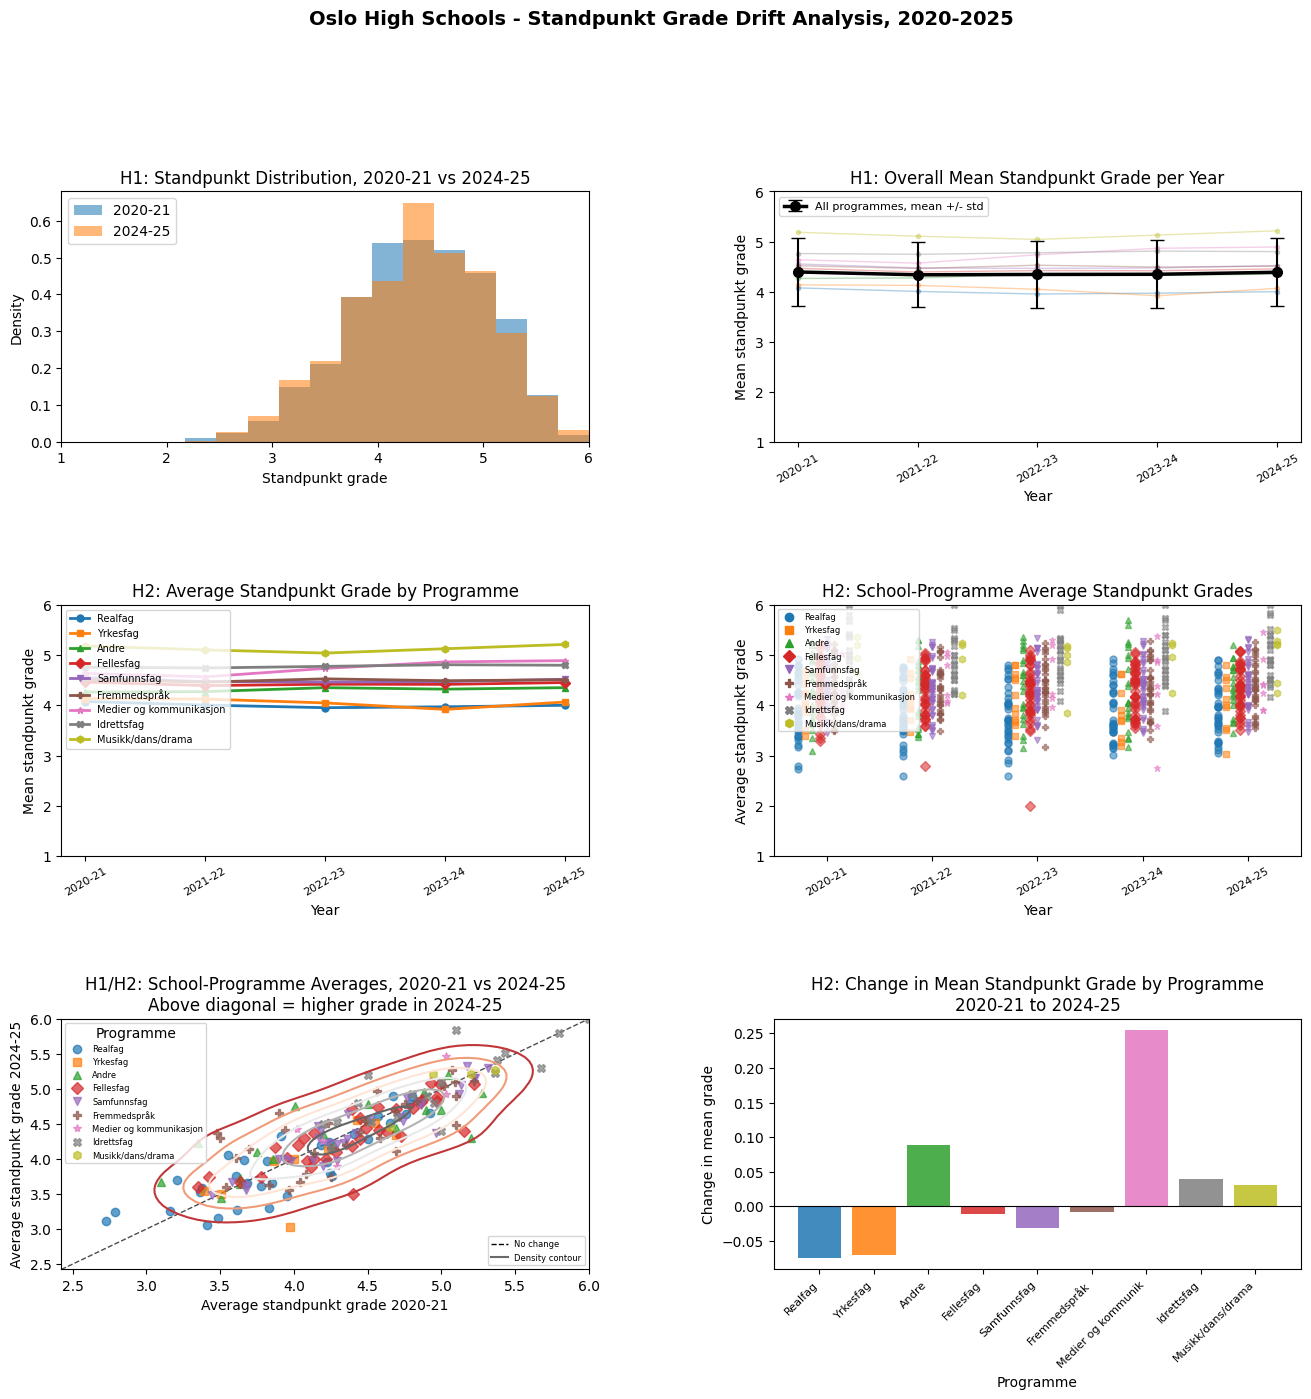


--| Interpretation |--
H1 weak/neutral: the overall weighted mean standpunkt grade changed by only -0.01 grade points from 2020-21 to 2024-25.
H2: Programme-level changes are mixed, so the drift is not equally strong across all programme groups.
This analysis uses standpunkt grades, so it measures school-set grade patterns across Oslo high schools.

Click OK to continue... (or enter if in terminal)

Which question do you want to run?
-----------------------------------
0. Exit
1. Question 1 - Supernacci
2. Question 2 - Dice Game
3. Question 3 - Coordinates
4. Question 4 - Matrix Trace
5. Question 5 - Case Study
-----------------------------------


Exiting...


In [91]:
menu()